In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('./data/giraffe-Kenya.png')

if img is None:
    print("Issue with image loading.")
else:
    print("Image loaded successfully.")

Image loaded successfully.


In [ ]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [9]:
img_g.shape, img_g.flatten().shape

((1600, 1067), (1707200,))

### On GRAY-SCALE image

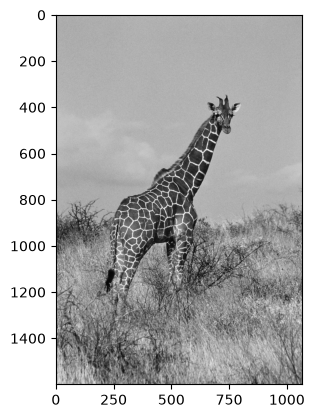

In [29]:
plt.imshow(img_g, 'gray')

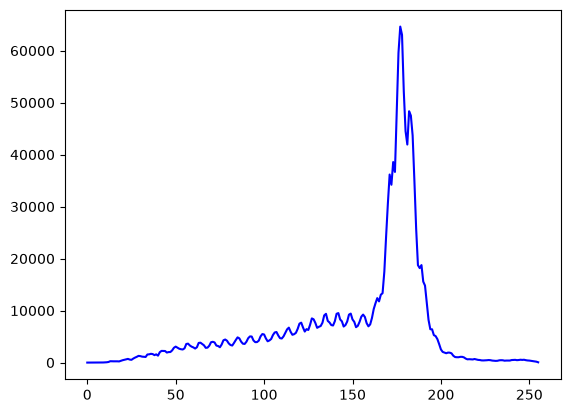

In [19]:
org_hist, bins = np.histogram(img_g.flatten(), bins=256, range=[0, 256])
plt.plot(org_hist, color='blue')

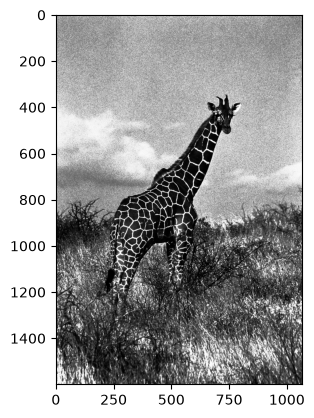

In [ ]:
# Histogram equalized gray scale
equalized_img_g = cv2.equalizeHist(img_g)
plt.imshow(equalized_img_g, 'grey')

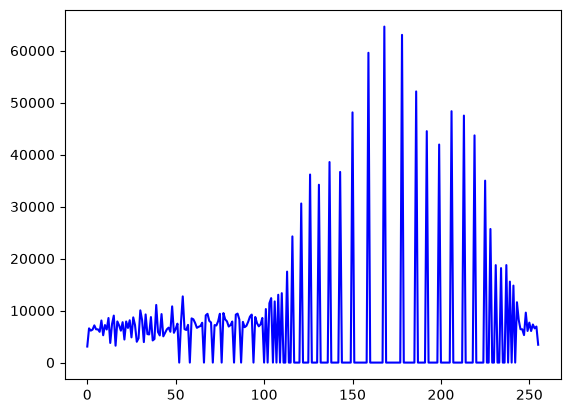

In [21]:
equalized_hist, bins = np.histogram(equalized_img_g.flatten(), bins=256, range=[0, 256])
plt.plot(equalized_hist, color='blue')

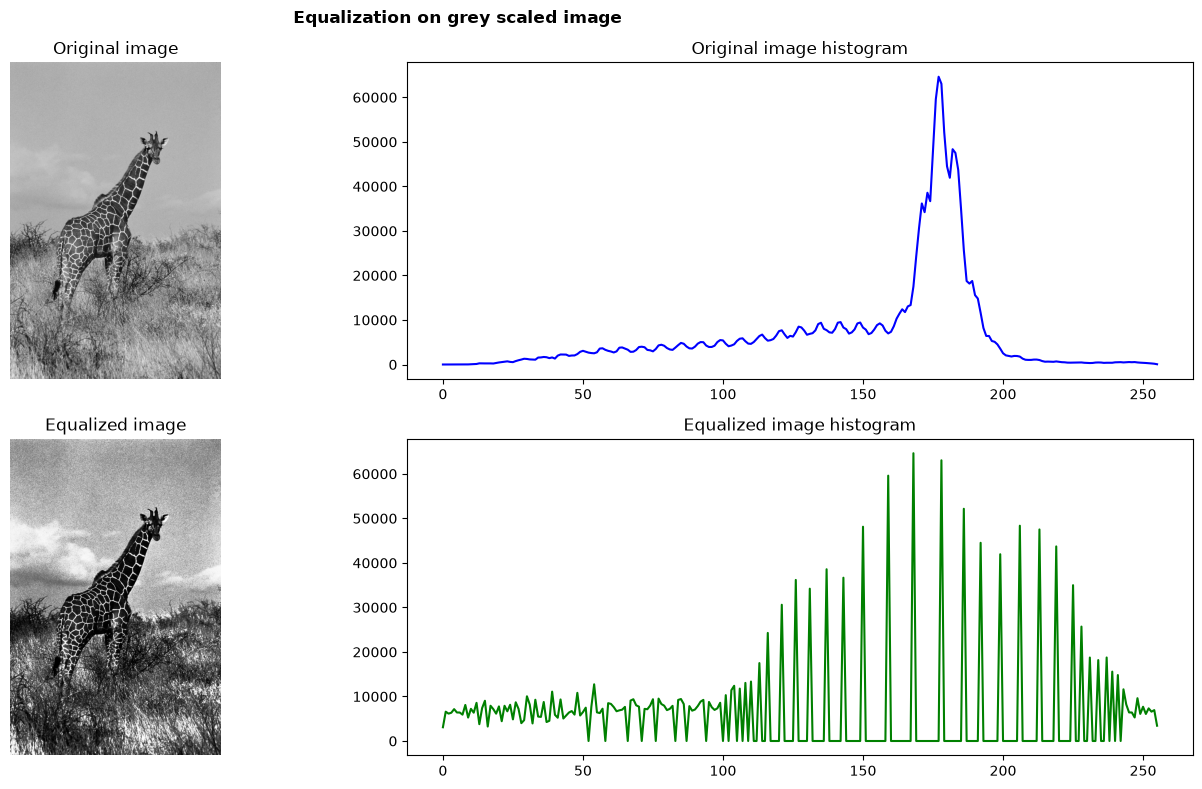

In [28]:
plt.figure(figsize=(15,8))

plt.subplot(2,2,1)
plt.imshow(img_g, 'grey')
plt.title("Original image")
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(equalized_img_g, 'grey')
plt.title("Equalized image")
plt.axis('off')

plt.subplot(2,2,2)
plt.plot(org_hist, color='blue')
plt.title("Original image histogram")

plt.subplot(2,2,4)
plt.plot(equalized_hist, color='green')
plt.title("Equalized image histogram")

plt.suptitle("Equalization on grey scaled image", weight='bold', size=12)
plt.tight_layout()

plt.savefig("./output/Image equlization grayscale.png")
plt.show()

### On RGB image

We cannot use the above method on RGB channels. We use channels like `LAB` and `YUV`. 

**$\underline{LAB}$**
| Channel | Meaning | Description |
|---|---|---|
| **L** | Lightness | Ranges from black to white. |
| **A** | Green–Red | Negative values indicate green; positive values indicate red. |
| **B** | Blue–Yellow | Negative values indicate blue; positive values indicate yellow. |


   


**$\underline{YUV}$**
| Channel | Meaning | Description |
|---|---|---|
| **Y** | Luma | Represents brightness information. |
| **U** | Blue projection | Represents a blue-related color difference. |
| **V** | Red projection | Represents a red-related color difference. |


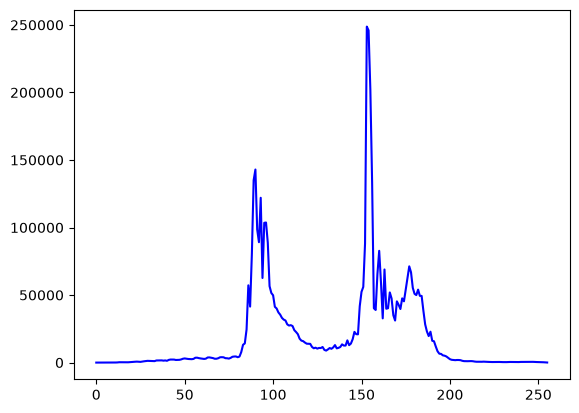

In [35]:
img_yuv = cv2.cvtColor(img, cv2.COLOR_BGR2YUV)
yuv_hist, bins = np.histogram(img_yuv.flatten(), bins=256, range=[0, 256])
plt.plot(yuv_hist, color='blue')

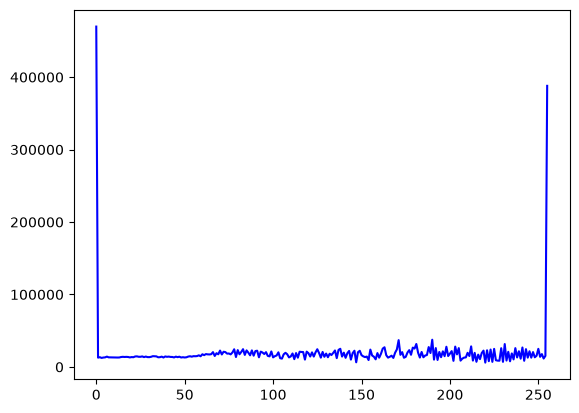

In [36]:
# Equalize only on the first channel (Y channel)
img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
equalized_img_rgb = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2RGB)
equalized_yuv_hist, bins = np.histogram(equalized_img_rgb.flatten(), bins=256, range=[0, 256])
plt.plot(equalized_yuv_hist, color='blue')

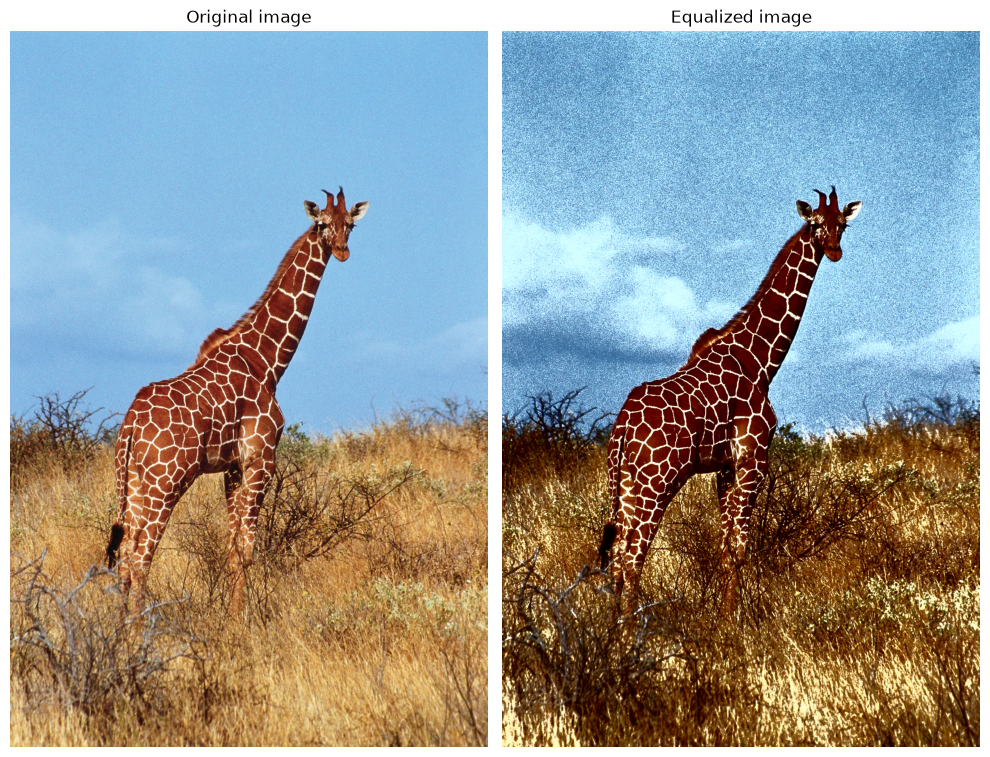

In [41]:
plt.figure(figsize=(10,8))

plt.subplot(1,2,1)
plt.imshow(img_rgb, 'grey')
plt.title("Original image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(equalized_img_rgb)
plt.title("Equalized image")
plt.axis('off')

plt.tight_layout()
plt.show()

Although the equalized image has a lot of noise, the brightness are balanced or shared with the surrounding.